# Two Solitudes

Nine hazards, English and French. The model only ever sees 4096 hashed counts of words and word pairs.
The training data is synthetic; the vault holds 1,369 real reports.

Plan of this notebook: look at the corpus, see why the first model fails, rebuild the training data, check on held-out
synthetic data and on hand-written probes, then open the vault.

In [1]:
import re, sys, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
import train as T
from train import CLASSES, featurize, bucket, tokens
from open_vault import load_sealed
from probes import PROBE
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 110)
raw = pd.read_csv(T.TASK / 'corpus.csv')
d = T.load_corpus()
Xs = load_sealed()
F = np.load(T.TASK / 'first_model.npz')
print(raw.shape, 'reports;', len(raw) - len(d), 'have a header and nothing else')

(9462, 3) reports; 90 have a header and nothing else


## 1. The corpus

In [2]:
raw['lang'] = raw.text.map(T.lang_of)
ct = pd.crosstab(raw.label, raw.lang)
ct['share_fr'] = (ct.fr / ct.sum(1)).round(2)
ct.sort_values('share_fr')

lang,en,fr,share_fr
label,,,
storm,740,310,0.30
transport,725,325,0.31
industrial,674,376,0.36
drought,545,505,0.48
ground,531,531,0.50
epidemic,490,560,0.53
flood,331,719,0.68
wildfire,322,728,0.69
winter,240,810,0.77


Classes are balanced, languages are not: flood, winter and wildfire are about 70% French, storm, transport and
industrial about 70% English. Any French word is evidence for flood/winter/wildfire in this corpus. That is the first
solitude.

In [3]:
first = raw.text.str.split(r'\. ', n=1, regex=True).str[0]
place = first.str.replace(r',.*', '', regex=True)
top = place.value_counts().head(8).index
pd.crosstab(place[place.isin(top)], raw.label[place.isin(top)])

label,drought,epidemic,flood,ground,industrial,storm,transport,wildfire,winter
text,,,,,,,,,
Central Saskatchewan,5,0,0,0,1,1,198,1,0
Centre de l'Ontario,1,9,36,1,0,66,0,0,0
Eastern Quebec,0,1,2,5,5,1,223,1,0
Est du Québec,0,6,29,1,62,1,0,4,6
Montréal QC,1,52,0,5,46,1,1,0,0
Nord de la Colombie-Britannique,0,1,1,3,54,0,0,62,0
Ouest de l'Alberta,2,4,1,58,54,0,0,3,0
Stephenville NL,0,0,0,5,0,36,3,0,61


Headers leak the label: 'Eastern Quebec' is a transport report 223 times out of 238. The synthetic reports come in
event clusters that share a place and a date.

In [4]:
S = T.sentences(d)
roles = S.k.map(T.template_roles(S))
print(roles.value_counts())
g = S[S.k == 'Soldiers assisted local authorities.']
print('Soldiers assisted local authorities. ->', g.y.map(lambda v: CLASSES[v]).value_counts().to_dict(),
      '| as first sentence:', g[g.pos == 0].y.map(lambda v: CLASSES[v]).value_counts().to_dict())

k
unk    16000
gen    13758
haz     5918
Name: count, dtype: int64
Soldiers assisted local authorities. -> {'storm': 73, 'flood': 28, 'industrial': 21, 'ground': 8, 'drought': 7, 'winter': 2, 'transport': 2} | as first sentence: {'storm': 58, 'industrial': 7, 'ground': 3, 'drought': 2}


About a fifth of the sentence templates are boilerplate (evacuations, damage in dollars, soldiers, Red Cross). They
appear under every hazard, yet each one leans to one class, and some reports contain nothing else: about 10% of the
reports name no hazard at all.

In [5]:
rx = re.compile(r'\b(oil spill|colliery|Hortense|ferry|traversier|influenza|grippe|smallpox|variole|ice storm|verglas)\b', re.I)
rows = []
for w in ['oil spill', 'colliery', 'Hortense', 'ferry', 'traversier', 'influenza', 'grippe', 'smallpox', 'variole', 'ice storm', 'verglas']:
    m = raw.text.str.contains(r'\b' + w + r'\b', case=False)
    rows.append({'term': w, **raw[m].groupby(['label', 'lang']).size().sort_values(ascending=False).head(3).to_dict()})
pd.DataFrame(rows).set_index('term').fillna('').astype(str)

,"(epidemic, en)","(industrial, en)","(transport, en)","(wildfire, en)","(storm, en)","(drought, en)","(ground, en)","(industrial, fr)","(transport, fr)","(winter, fr)","(epidemic, fr)","(storm, fr)"
term,,,,,,,,,,,,
oil spill,61.0,2.0,1.0,,,,,,,,,
colliery,,13.0,,69.0,,,,,,,,
Hortense,,,234.0,,4.0,1.0,,,,,,
ferry,,7.0,285.0,,,,1.0,,,,,
traversier,,,,,,,,70.0,1.0,1.0,,
influenza,16.0,,,,,,,,,,,
grippe,,,,,,,,,,,102.0,
smallpox,4.0,,,,,,,,,,,
variole,,,,,,,,,,,52.0,


Two more patterns. Sentences about one hazard are planted inside reports of another, each pairing mostly in one
language (oil spills inside English epidemic reports, a named tropical storm inside English transport reports). And
whole sub-hazards live in one language only: influenza, smallpox and ice storms are French-only words here, ferries and
shipwrecks English-only. A real English ice storm report has nothing to match.

## 2. What goes wrong with the first model

In [6]:
terms = collections.defaultdict(collections.Counter)
for t in raw.text:
    tk = tokens(t)
    for x in tk + [a + ' ' + b for a, b in zip(tk, tk[1:])]:
        terms[bucket(x)][x] += 1
W0, b0 = F['W'], F['b']
print('bias b:', dict(zip(CLASSES, b0.round(2))))
for c in range(9):
    top = np.argsort(-W0[c])[:8]
    print(f'{CLASSES[c]:10s}', ', '.join(terms[j].most_common(1)[0][0] for j in top))

bias b: {'flood': np.float32(0.11), 'storm': np.float32(-0.21), 'winter': np.float32(-0.14), 'wildfire': np.float32(-0.96), 'drought': np.float32(-0.03), 'ground': np.float32(1.09), 'industrial': np.float32(0.63), 'transport': np.float32(-0.43), 'epidemic': np.float32(-0.06)}
flood      la rivière, mai 0, flooding, river, avril 0, eaux, avril, bridges
storm      pe, september 0, newfoundland, sydney, summerside, july 0, quebec october, chutes de
winter     décembre 0, février, février 0, décembre, janvier 0, janvier, mars, snow
wildfire   0 hectares, forêt, hectares, de forêt, feux, yellowknife, juin, juin 0
drought    drought, récoltes sont, sk, crops, mb, sécheresse, august, ab
ground     avalanche, un, bc, la nouvelle-écosse, a, buried, road, felt
industrial qc, val-d'or, explosion, lytton, rivière, températures près, fire, ontario
transport  train, passagers, à, 0 passagers, 0 others, 0 people, et 0, the loss
epidemic   0 cas, cas, 0 cases, cases, d'urgence, deaths, polio, reported

Its strongest cells are places, months and template words. Its bias b is large (ground +1.1, industrial +0.6).
Real reports are longer than synthetic ones (about 117 non-zero cells against 66), so after normalisation the word part
of the score shrinks and the bias decides more often.

In [7]:
en, fr = T.language_of_rows(Xs)
def by_language(W, b):
    p = (Xs @ W.T + b).argmax(1)
    pe = np.bincount(p[en], minlength=9) / en.sum(); pf = np.bincount(p[fr], minlength=9) / fr.sum()
    return pd.DataFrame({'English': (100 * pe).round(0), 'French': (100 * pf).round(0)}, index=CLASSES).T, 0.5 * np.abs(pe - pf).sum()
tab, tv = by_language(W0, b0)
print('first model, share of predicted hazards (%) by report language; total variation', round(tv, 3))
tab

first model, share of predicted hazards (%) by report language; total variation 0.31


,flood,storm,winter,wildfire,drought,ground,industrial,transport,epidemic
English,11.0,13.0,4.0,5.0,12.0,20.0,21.0,5.0,9.0
French,23.0,12.0,13.0,15.0,6.0,10.0,9.0,4.0,7.0


Nothing says real English and French reports differ in their mix of hazards. The first model sorts them very
differently (a third of the mass moves): French reports go to flood, winter and wildfire, English ones to ground and
industrial. It reads the language, not the hazard.

## 3. What changed

`train.py`, in short:

1. Split each report into header and sentences.
2. Find hazard sentences. Boilerplate templates are those spread over many hazards. A ten-class sentence model
   (nine hazards + boilerplate) is trained on first sentences, out-of-fold by event, two rounds. A sentence takes the
   hazard the model gives it, so a planted oil-spill sentence counts as industrial, wherever it sits. A word list check
   drops hazard sentences whose hazard words point elsewhere.
3. Rebuild reports: hazard sentence(s) of one class + random boilerplate + a random header + sometimes a sentence of
   another hazard, the same number per class and language. Boilerplate and headers carry no label any more.
4. Make the two languages talk: hazard terms are swapped into the other language (PAIRS), common words too (GENERAL),
   synonyms are swapped (SYN), and 15% of the hazard sentences come from a small hand-written set (EXTRA). Place names
   are shuffled, words dropped at random.
5. Ignore cells that cannot be trusted: function words and their pairs, and hash collisions found from how often each
   cell is non-zero in the sealed fingerprints compared with training (overall and per language). This is the only use
   of the sealed fingerprints: marginal counts, no labels, no pseudo-labels.
6. Eight logistic regressions on differently augmented sets, averaged; b = 0. A small season term on month cells for
   the weather hazards.

In [8]:
S2, cls, P = None, None, None
d_, S2, cls, P = T.prepare()
nat, gen, heads, names = P
print({CLASSES[c] + '/' + l: len(v) for (c, l), v in nat.items()})
print('boilerplate pool', {l: len(v) for l, v in gen.items()})

sentences 35676 hazard 13438 boilerplate 17025 dropped 5213
{'flood/en': 482, 'flood/fr': 1522, 'storm/en': 1017, 'storm/fr': 543, 'winter/en': 372, 'winter/fr': 994, 'wildfire/en': 556, 'wildfire/fr': 1505, 'drought/en': 759, 'drought/fr': 599, 'ground/en': 684, 'ground/fr': 720, 'industrial/en': 637, 'industrial/fr': 451, 'transport/en': 978, 'transport/fr': 379, 'epidemic/en': 609, 'epidemic/fr': 631}
boilerplate pool {'en': 9658, 'fr': 7367}


In [9]:
rng = np.random.default_rng(0)
tx, ty = T.generate(P, 1, rng)
for t, y in list(zip(tx, ty))[::4]:
    print(f'[{CLASSES[y]}]', t[:220])

[flood] On September 8, 1978, in Southern Nova Scotia. The Trans-Canada Highway was closed. The ferry off coast with loss 6 More than were 5,711 were Severe flooding farmland and homes as rivers rose. High water submerged roads 
[winter] On April 13, 1954, near Chilliwack BC. récoltes were lost. snow and cold closed schools and for Faulty wiring was 67 were killed. About 589208 power. Heavy snowfall closed and stranded
[drought] earthquake felt across the region, were Two of drought grain
[industrial] 22 481 évacuées. 5 were blamed excessive speed. snowstorm and strong winds stranded motorists two days. fire out in and spread quickly to downtown totaux 9 dollars.
[epidemic] Eastern Quebec, September 1978. people taken hospital. The éclosion spread from banned. 530 endommagées. Soldiers assisted local


## 4. Proxy validation on held-out synthetic data

Two harder splits: by event (header), and by template family (first two words of the opening sentence, so the test
phrasing is unseen). Test sets: T1 held-out reports as written; T2 their opening hazard sentences; T3 those hazard
sentences rebuilt with random headers and boilerplate (labels no longer leak); T4 = T3 with 0-80 random words added
(stand-in for unseen real vocabulary). Scores are mean accuracy over the 18 class x language cells.
Models: A = first-model recipe retrained on the split, B = A without headers and with language weights, ours = one
member of the bag (the sealed-based cell mask is left out here).

In [10]:
def cell_acc(p, y, l):
    return pd.DataFrame({'ok': p == y, 'y': y, 'l': l}).groupby(['y', 'l']).ok.mean().mean()

def junk(rng, k):
    a = 'abcdefghijklmnopqrstuvwxyz'
    return ' '.join(''.join(a[i] for i in rng.integers(0, 26, rng.integers(3, 10))) for _ in range(k))

def run_split(kind, seed=0):
    grp = d.event if kind == 'event' else d.body.map(lambda b: ' '.join(re.sub(r'\d+', '0', b[0].lower()).split()[:2]))
    tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(d, d.y, grp))
    dtr, dte = d.iloc[tr], d.iloc[te]
    out = {}
    Str, Ste = T.sentences(dtr), T.sentences(dte)
    ctr = T.lexicon_check(Str, T.sentence_classes(Str, featurize(Str.text.tolist())))
    cte = T.lexicon_check(Ste, T.sentence_classes(Ste, featurize(Ste.text.tolist())))
    Ptr, Pte = T.pools(dtr, Str, ctr), T.pools(dte, Ste, cte)
    rng = np.random.default_rng(7)
    t3, y3 = T.generate((Pte[0], Ptr[1], Pte[2], Pte[3]), 60, rng, p_syn=0, p_tr=0, p_gtr=0, p_drop=0, p_extra=0,
                        p_names=0, p_second=0, p_distract=0)
    l3 = np.tile(np.repeat(['en', 'fr'], 60), 9)
    m2 = (Ste.pos.values == 0) & (cte == Ste.y.values)
    tests = {'T1 reports': (featurize(dte.text.tolist()), dte.y.values, dte.lang.values),
             'T2 hazard sentence': (featurize(Ste.text[m2].tolist()), Ste.y.values[m2], Ste.lang.values[m2]),
             'T3 rebuilt': (featurize(t3), y3, l3),
             'T4 rebuilt + noise': (featurize([t + ' ' + junk(rng, int(rng.integers(0, 80))) for t in t3]), y3, l3)}
    mA = T.fit_lr(featurize(dtr.text.tolist()), dtr.y.values, C=10)
    mB = T.fit_lr(featurize([' '.join(b) for b in dtr.body]), dtr.y.values, T.balance_weights(dtr.y.values, dtr.lang.values), C=10)
    tx, ty = T.generate(Ptr, 500, np.random.default_rng(1))
    mask = T.function_cells(dtr.text.tolist())
    Xg = featurize(tx); Xg[:, mask] = 0
    mC = T.fit_lr(Xg, ty, C=3)
    for name, m, use_b in [('A first recipe', mA, True), ('B no header + language weights', mB, False), ('ours (one member)', mC, False)]:
        W = np.zeros((9, 4096)); W[m.classes_] = m.coef_; b = np.zeros(9)
        if use_b: b[m.classes_] = m.intercept_
        if name.startswith('ours'): W[:, mask] = 0
        out[name] = {t: round(cell_acc((X @ W.T + b).argmax(1), y, l), 3) for t, (X, y, l) in tests.items()}
    return pd.DataFrame(out).T

res_event = run_split('event'); res_event

,T1 reports,T2 hazard sentence,T3 rebuilt,T4 rebuilt + noise
A first recipe,0.904,0.930,0.762,0.692
B no header + language weights,0.856,0.949,0.782,0.715
ours (one member),0.711,0.965,0.966,0.902


In [11]:
res_family = run_split('family'); res_family

,T1 reports,T2 hazard sentence,T3 rebuilt,T4 rebuilt + noise
A first recipe,0.870,0.883,0.651,0.573
B no header + language weights,0.804,0.939,0.719,0.652
ours (one member),0.616,0.888,0.894,0.827


On reports written like the training ones (T1) the first recipe wins: it uses the leaks. As soon as the label can
only come from the hazard sentence (T3, T4) it drops to 0.57-0.76, while the rebuilt training keeps 0.83-0.97, also on
phrasing it has never seen (template-family split).

## 5. Hand-written probes

180 short reports I wrote for testing only (ten per hazard and language, `probes.py`), each with a random header and
1-3 boilerplate sentences from the corpus.

In [12]:
rng = np.random.default_rng(42)
S_, Y_, L_ = [], [], []
for c, g in PROBE.items():
    for l, v in g.items():
        for s in v:
            S_.append(s); Y_.append(CLASSES.index(c)); L_.append(l)
Y_ = np.array(Y_); L_ = np.array(L_)
docs = []
for s, l in zip(S_, L_):
    b = [s] + [gen[l][rng.integers(len(gen[l]))] for _ in range(rng.integers(1, 4))]
    rng.shuffle(b)
    docs.append(heads[l][rng.integers(len(heads[l]))] + ' ' + ' '.join(b))
Xp = featurize(docs)
M = np.load('model.npz')
rows = {}
for name, W, b in [('first model', F['W'], F['b']), ('final model', M['W'], M['b'])]:
    p = (Xp @ W.T + b).argmax(1)
    rows[name] = {'all': round((p == Y_).mean(), 3), 'English': round((p[L_ == 'en'] == Y_[L_ == 'en']).mean(), 3),
                  'French': round((p[L_ == 'fr'] == Y_[L_ == 'fr']).mean(), 3),
                  **{c: round((p[Y_ == i] == i).mean(), 2) for i, c in enumerate(CLASSES)}}
pd.DataFrame(rows).T

,all,English,French,flood,storm,winter,wildfire,drought,ground,industrial,transport,epidemic
first model,0.339,0.367,0.311,0.1,0.5,0.30,0.40,0.25,0.6,0.35,0.25,0.3
final model,0.806,0.811,0.800,0.7,0.9,0.85,0.85,0.85,0.7,0.70,0.80,0.9


## 6. The final model on the sealed fingerprints

In [13]:
W, b = M['W'], M['b']
sc = Xs @ W.T + b
p = sc.argmax(1)
tab, tv = by_language(W, b)
print('predicted hazards:', dict(zip(CLASSES, np.bincount(p, minlength=9).tolist())))
print('share by report language (%); total variation', round(tv, 3))
tab

predicted hazards: {'flood': 328, 'storm': 226, 'winter': 119, 'wildfire': 150, 'drought': 89, 'ground': 79, 'industrial': 176, 'transport': 129, 'epidemic': 73}
share by report language (%); total variation 0.103


,flood,storm,winter,wildfire,drought,ground,industrial,transport,epidemic
English,24.0,17.0,6.0,12.0,5.0,5.0,15.0,10.0,5.0
French,26.0,18.0,11.0,11.0,7.0,4.0,10.0,7.0,6.0


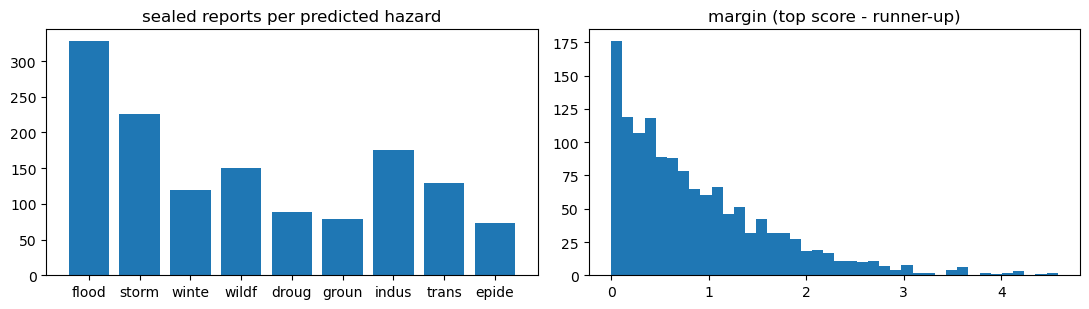

In [14]:
s = np.sort(sc, 1); mg = s[:, -1] - s[:, -2]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar([c[:5] for c in CLASSES], np.bincount(p, minlength=9)); ax[0].set_title('sealed reports per predicted hazard')
ax[1].hist(mg, bins=40); ax[1].set_title('margin (top score - runner-up)')
plt.tight_layout(); plt.show()

## 7. Vault

Attempts, in order (one run each):

| # | model | result |
|---|---|---|
| 1 | rebuilt reports, language balance, function cells zeroed | nothing |
| 2 | + word list check on hazard sentences, synonym swaps | nothing |
| 3 | + hand-written sentences, place-name swaps | nothing |
| 4 | + self-training on sealed fingerprints (model's own surest labels) | nothing |
| 5 | + English/French term swaps | nothing |
| 6 | report-level training, cross-hazard sentences kept | nothing |
| 7 | 5 + month-preserving headers | nothing |
| 8 | provided first_model.npz | SNOWBLIND (the baseline says this is not the flag) |
| 9 | report-level, cross-hazard sentences mirrored across languages | nothing |
| 10 | bag of 8, 'flooding' no longer shared with storm, collision cells, season term | SNOWFLAKE |
| 11 | this `train.py` from scratch (agrees with #10 on 91% of reports) | SNOWFLAKE |
| 12 | this notebook, same model.npz | below |

Attempt 4 was the only one that used the sealed fingerprints beyond marginal counts; it is not in the final model.

In [15]:
import subprocess
r = subprocess.run([sys.executable, str(T.TASK / 'open_vault.py'), 'model.npz'], capture_output=True, text=True)
print(r.stdout, r.stderr)

The vault releases: SIGMOID_SNOWFLAKE
 
